In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles

In [2]:
np.random.seed(42)
X, y = make_circles(n_samples=500, factor=0.1, noise=0.35, random_state=42)

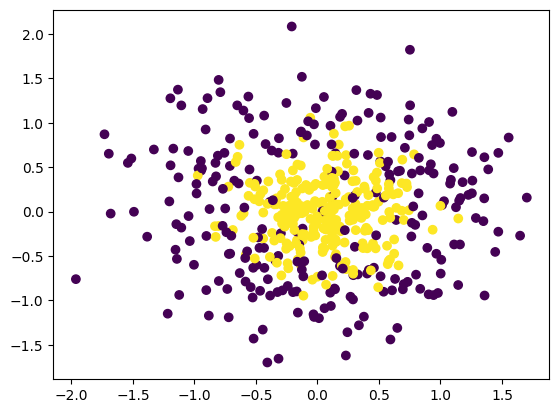

In [3]:
plt.scatter(X[:,0],X[:,1],c=y)

In [4]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

In [5]:
abc = AdaBoostClassifier()

In [6]:
np.mean(cross_val_score(abc,X,y,cv = 10,scoring='accuracy'))

np.float64(0.812)

In [7]:
abc.fit(X,y)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None


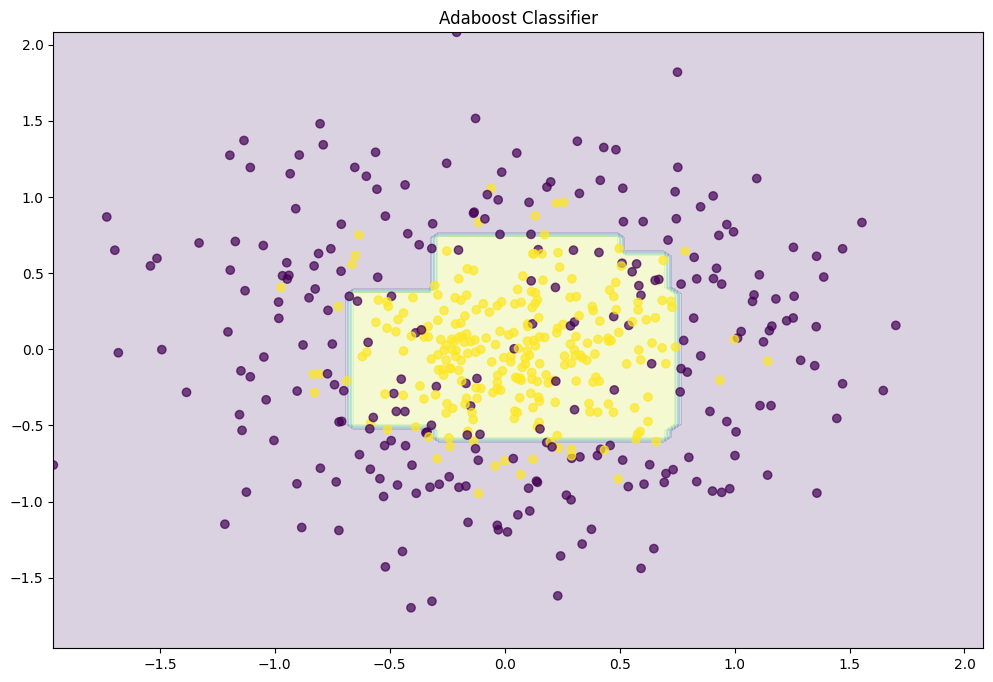

In [8]:
def plot_decision_boundary(clf):
    plt.figure(figsize=(12, 8))
    x_range = np.linspace(X.min(), X.max(), 100)
    xx1, xx2 = np.meshgrid(x_range, x_range)
    y_hat = clf.predict(np.c_[xx1.ravel(), xx2.ravel()])
    y_hat = y_hat.reshape(xx1.shape)
    plt.contourf(xx1, xx2, y_hat, alpha=0.2)
    plt.scatter(X[:,0], X[:,1], c=y, cmap='viridis', alpha=.7)
    plt.title("Adaboost Classifier")
    plt.show()
    
plot_decision_boundary(abc)

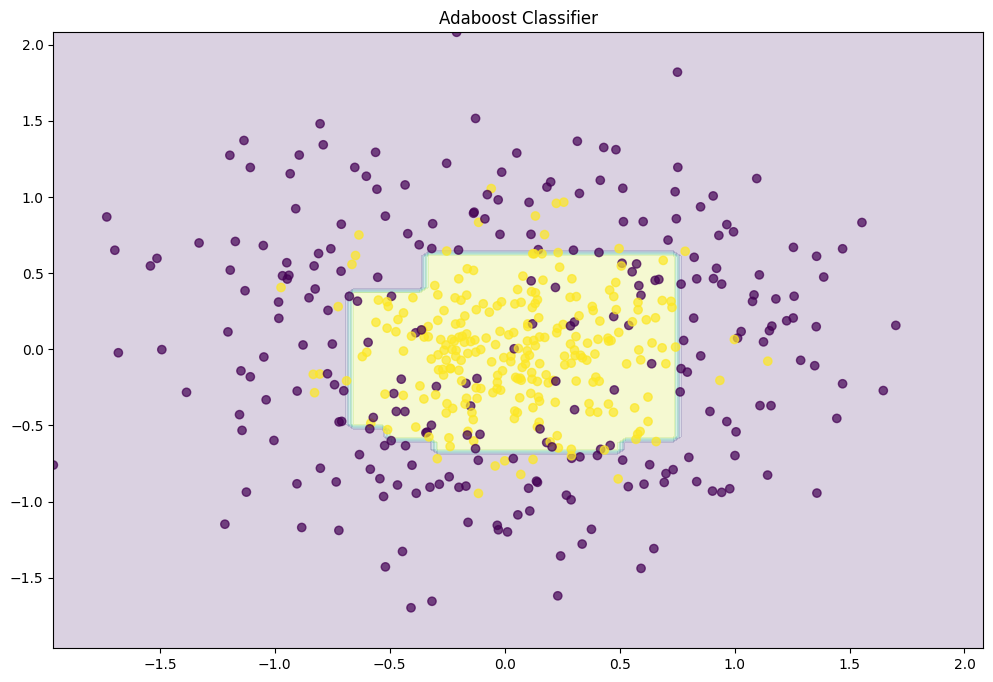

In [14]:
abc = AdaBoostClassifier(n_estimators=1000,learning_rate=0.1)
abc.fit(X,y)
plot_decision_boundary(abc)

In [15]:
from sklearn.model_selection import GridSearchCV

In [17]:
grid = dict()
grid['n_estimators'] = [25,88,160,450,700]
grid['learning_rate'] = [1,0.1,0.001,0.5]
grid['algorithm'] = ['SAMME']

grid_search = GridSearchCV(estimator = AdaBoostClassifier(),param_grid = grid ,n_jobs = -1,cv=10,scoring='accuracy')
grid_result = grid_search.fit(X,y)
print("Best: %f using %s" % (grid_result.best_score_, grid_result.best_params_))

C:\Users\Harshgupta\anaconda3\envs\harsenv\lib\site-packages\sklearn\ensemble\_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


Best: 0.832000 using {'algorithm': 'SAMME', 'learning_rate': 0.1, 'n_estimators': 450}
